In [1]:
## Run from scvi environment
## Need specific scanpy versions to be able to properly read cellbender formats|

In [2]:
import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import muon as mu
from muon import MuData

import scvi
import session_info

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from single_cell_utils import *

In [3]:
%config InlineBackend.figure_format = 'retina'

In [4]:
session_info.show()

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [5]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/gex_adata/tf_pilot/batch1/ipsc/'

In [6]:
adata = sc.read_h5ad(work_dir + 'leiden_v1/adata_leiden_v3.h5ad')

In [7]:
adata

AnnData object with n_obs × n_vars = 9942 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5

In [9]:
adata.X = adata.layers['counts'].copy()

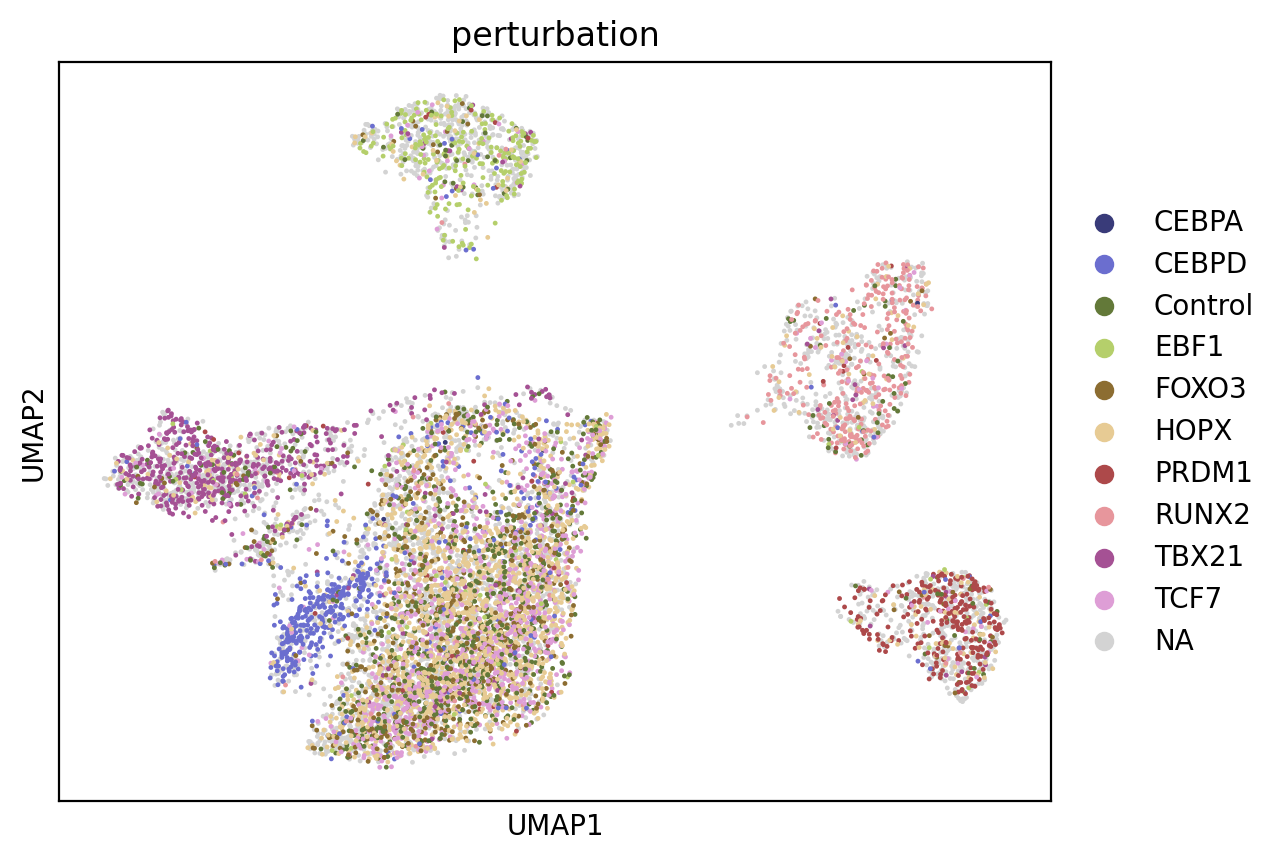

In [10]:
sc.pl.umap(adata, color=['perturbation'])

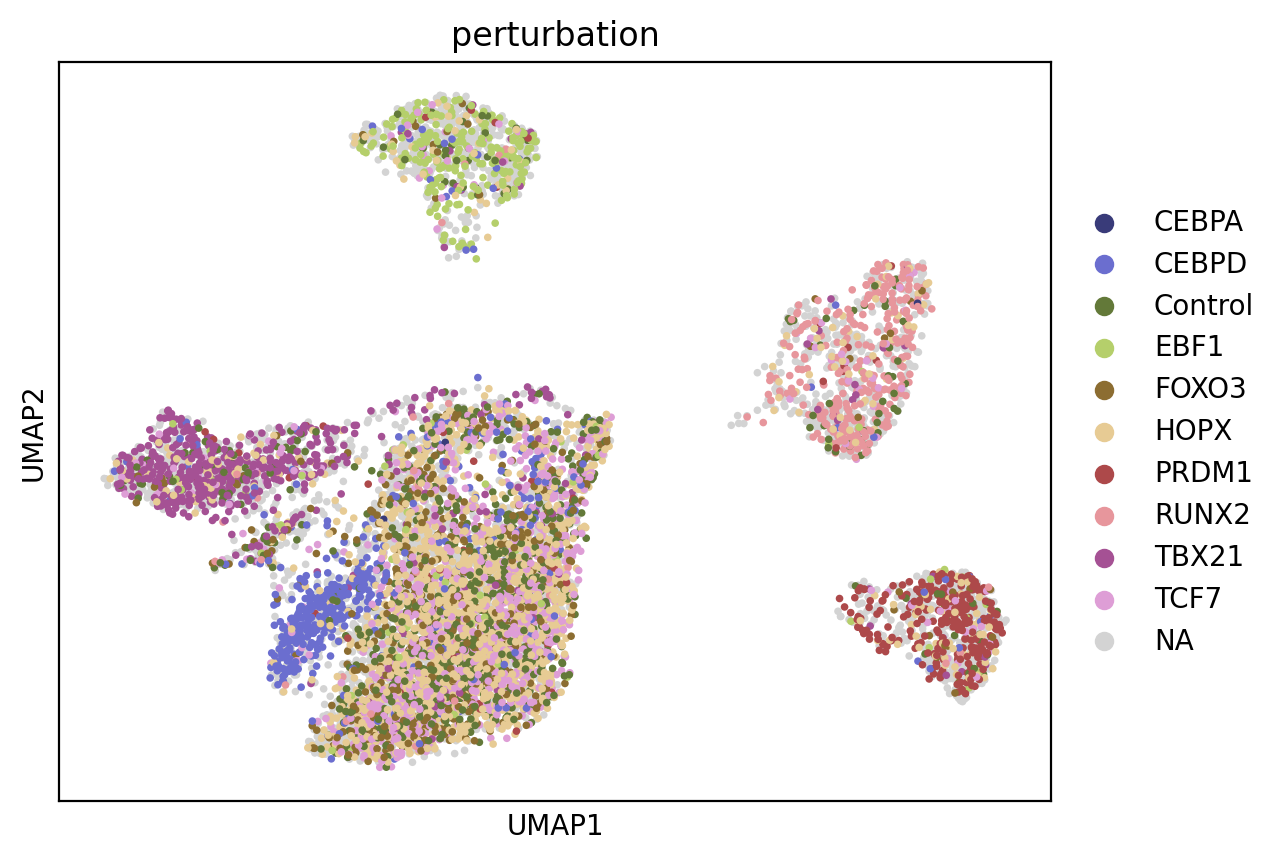

In [11]:
sc.pl.umap(adata, color=['perturbation'], size=30, palette='tab20b')

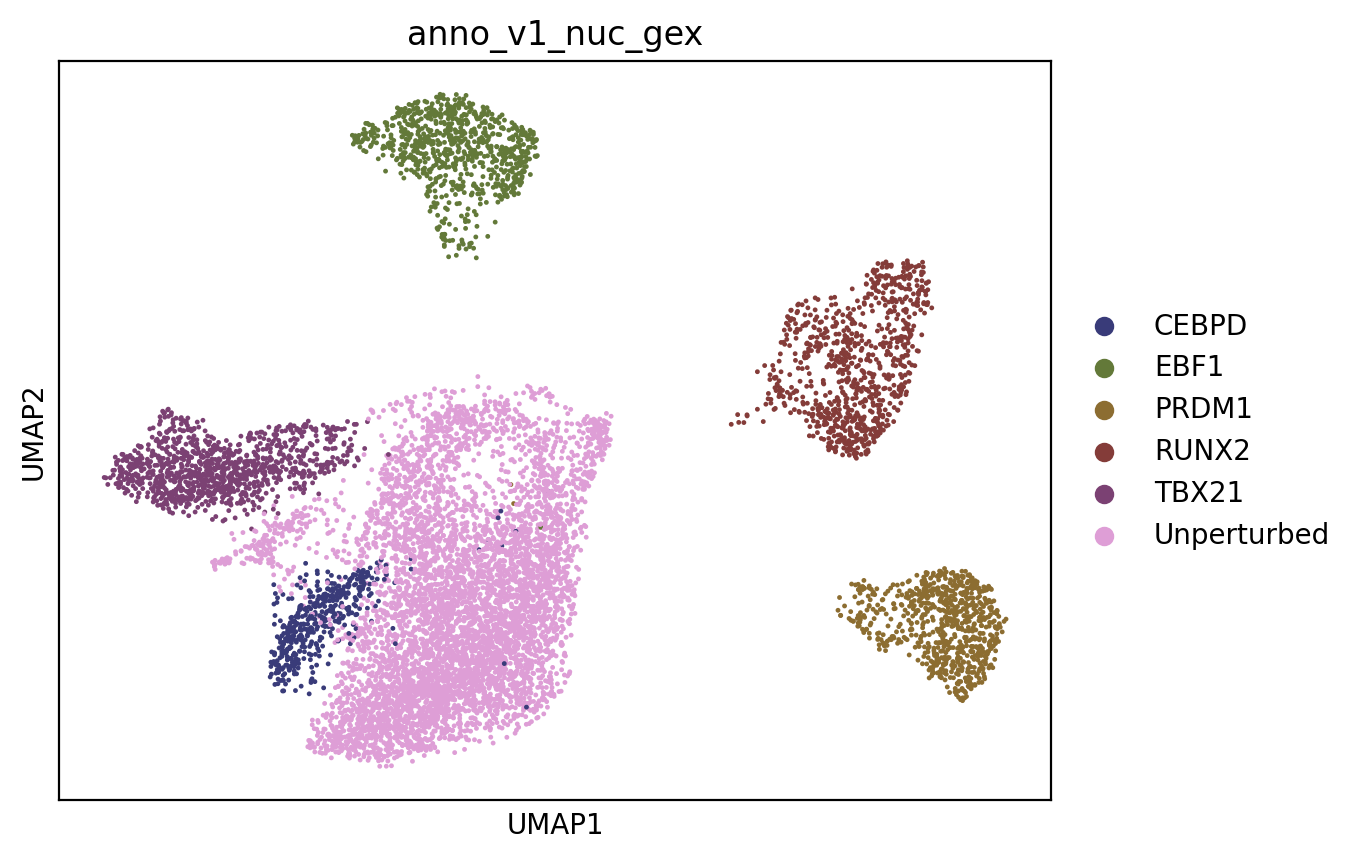

In [12]:
sc.pl.umap(adata, color=['anno_v1_nuc_gex'])

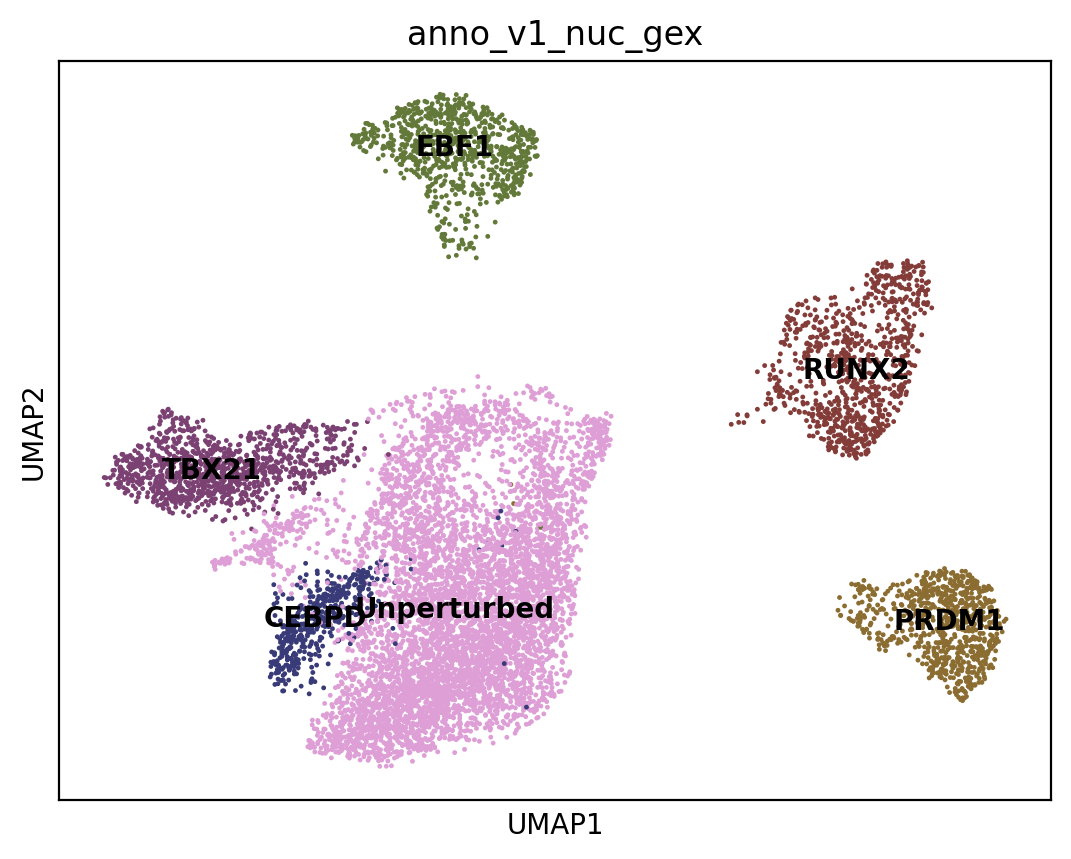

In [13]:
sc.pl.umap(adata, color=['anno_v1_nuc_gex'], legend_loc='on data')

In [21]:
pos2 = ['Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2']

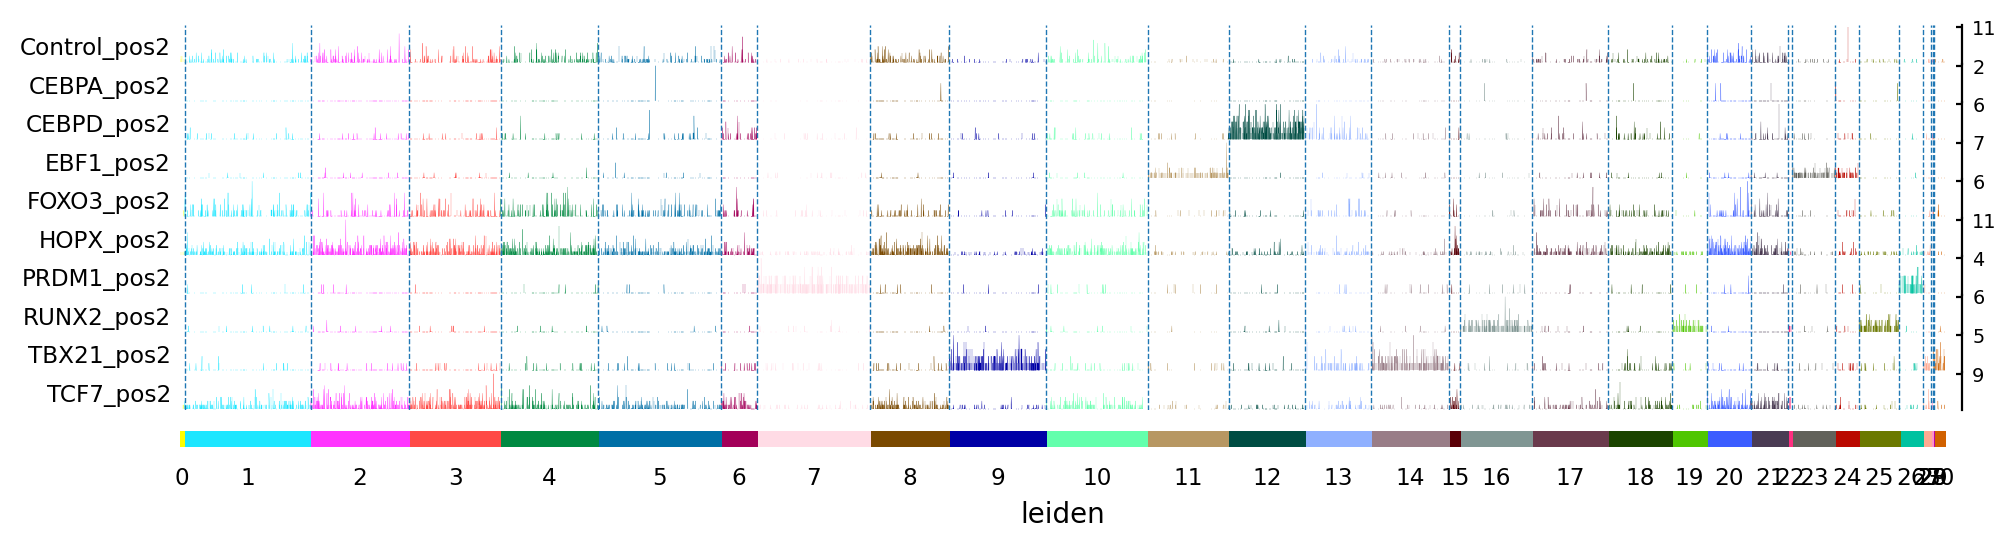

In [22]:
sc.pl.tracksplot(adata, pos2, groupby='leiden')

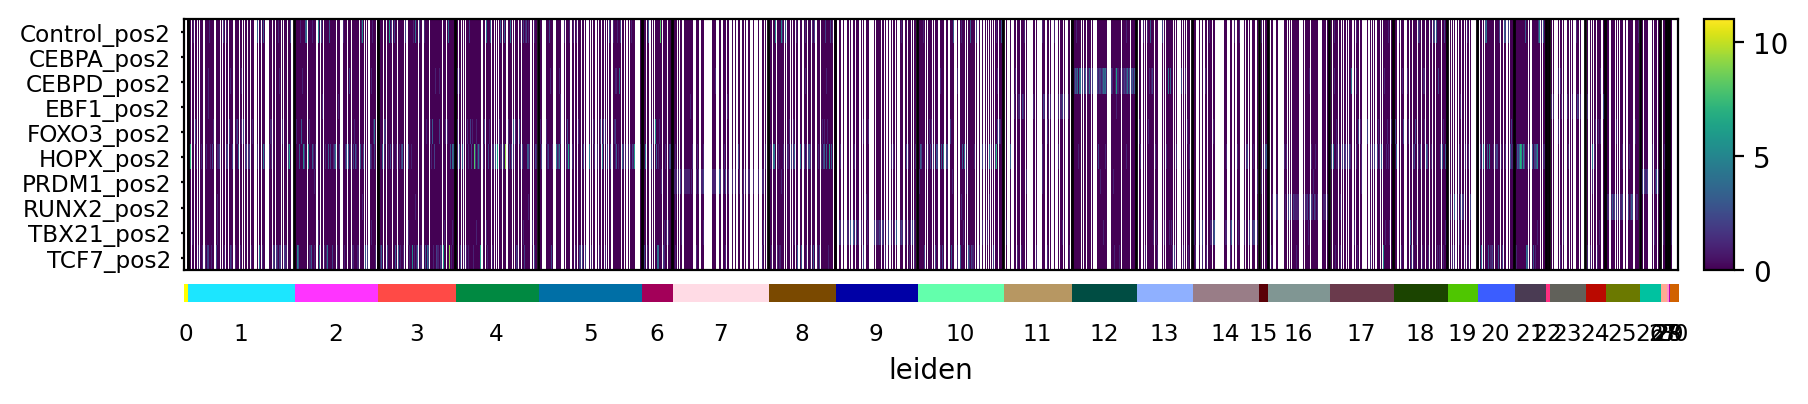

In [23]:
sc.pl.heatmap(adata, pos2, groupby='leiden', swap_axes=True)

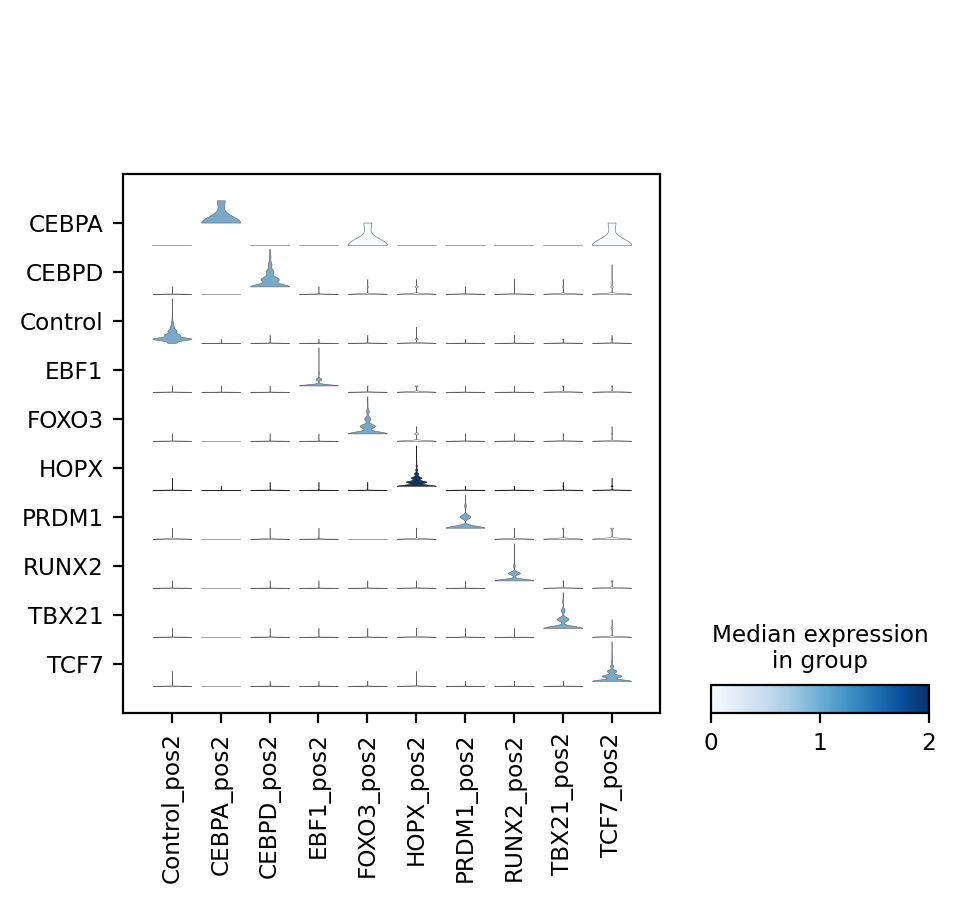

In [24]:
sc.pl.stacked_violin(adata, pos2, groupby='perturbation')

In [25]:
tfs = ['CEBPA', 'CEBPD', 'EBF1', 'FOXO3', 'HOPX', 'PRDM1', 'RUNX2', 'TBX21', 'TCF7']

In [26]:
tfs_ctrl = ['Control', 'CEBPA', 'CEBPD', 'EBF1', 'FOXO3', 'HOPX', 'PRDM1', 'RUNX2', 'TBX21', 'TCF7']

In [27]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['perturbation'], categories=tfs_ctrl, ordered=True
)

In [31]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)

# Logarithmize the data
sc.pp.log1p(adata)

In [32]:
# Subset to perturbed iPSC
adata_ipsc_perturbed = adata[adata.obs['perturbation'].notna()]

In [33]:
## Find neighbors, run Leiden clustering and UMAP
sc.pp.highly_variable_genes(adata_ipsc_perturbed)
sc.pp.pca(adata_ipsc_perturbed)
sc.pp.neighbors(adata_ipsc_perturbed)
sc.tl.leiden(adata_ipsc_perturbed)
sc.tl.umap(adata_ipsc_perturbed)

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:664: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["hvg"] = {"flavor": flavor}
/tmp/ipykernel_2018954/2600827018.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_ipsc_perturbed)


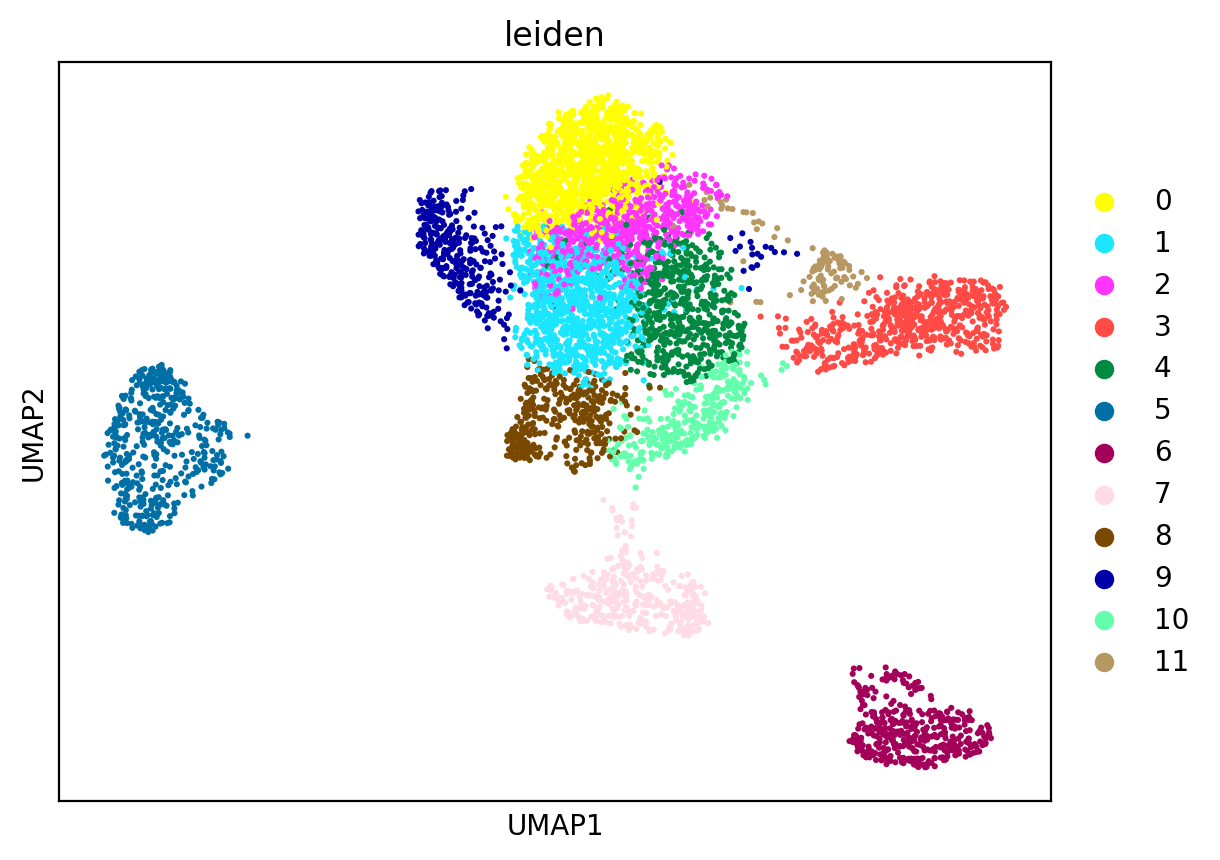

In [34]:
sc.pl.umap(adata_ipsc_perturbed, color=['leiden'])

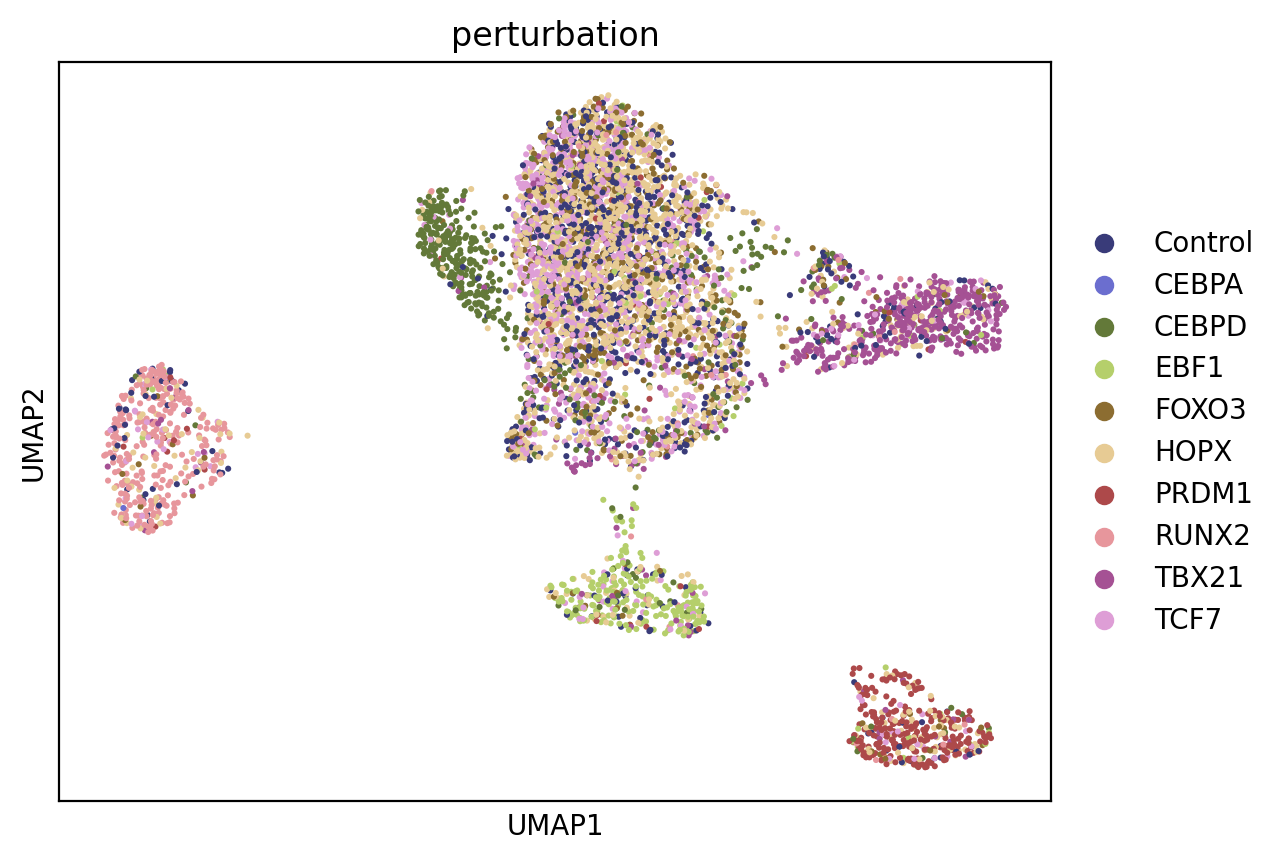

In [35]:
sc.pl.umap(adata_ipsc_perturbed, color=['perturbation'])

In [36]:
# Save object
adata_ipsc_perturbed.write_h5ad(work_dir + 'leiden_v1/adata_leiden_v3_ipsc_perturbed.h5ad')

In [37]:
## And export annotation
adata_ipsc_perturbed.obs.to_csv(work_dir + 'leiden_v1/adata_multi_ipsc_perturbed_anno_v1_nuc_gex.csv')

In [9]:
adata_ipsc_perturbed = sc.read_h5ad(work_dir + 'leiden_v1/adata_leiden_v3_ipsc_perturbed.h5ad')

In [15]:
adata_ipsc_perturbed

AnnData object with n_obs × n_vars = 6192 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden', 'amulet_doublet', 'is_valid_doublet', 'v1_leiden_100', 'v2_leiden_1.5', 'anno_v1_nuc_gex', 'v3_leiden_1.5

<Axes: title={'center': 'perturbation'}, xlabel='UMAP1', ylabel='UMAP2'>

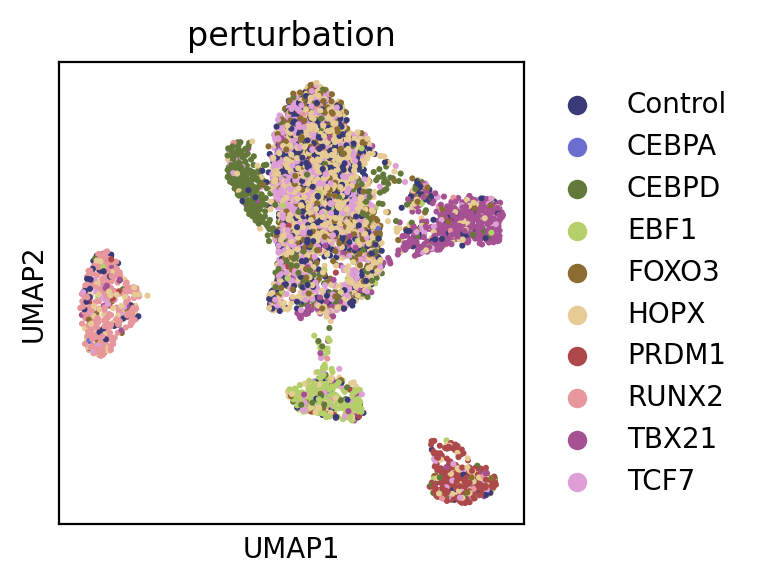

In [18]:
fig, ax = plt.subplots(figsize=(3, 3))
sc.pl.umap(adata_ipsc_perturbed, color=['perturbation'], ax=ax, show=False)

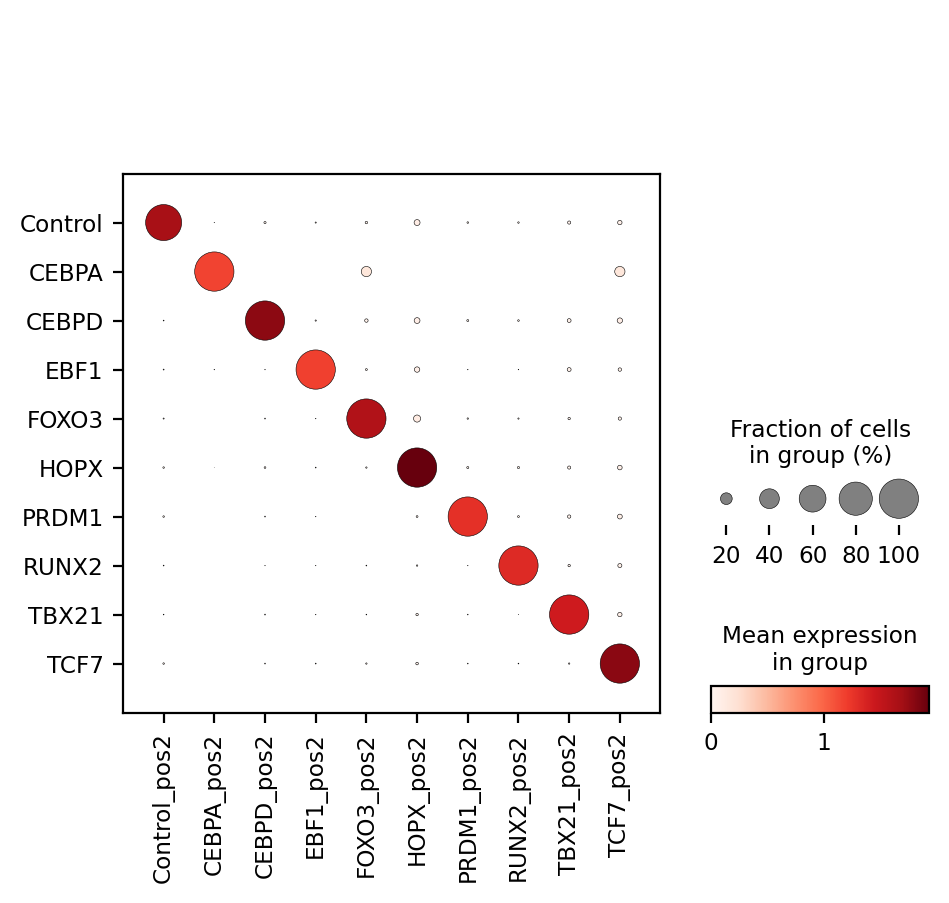

In [39]:
sc.pl.dotplot(adata, pos2, groupby='perturbation')

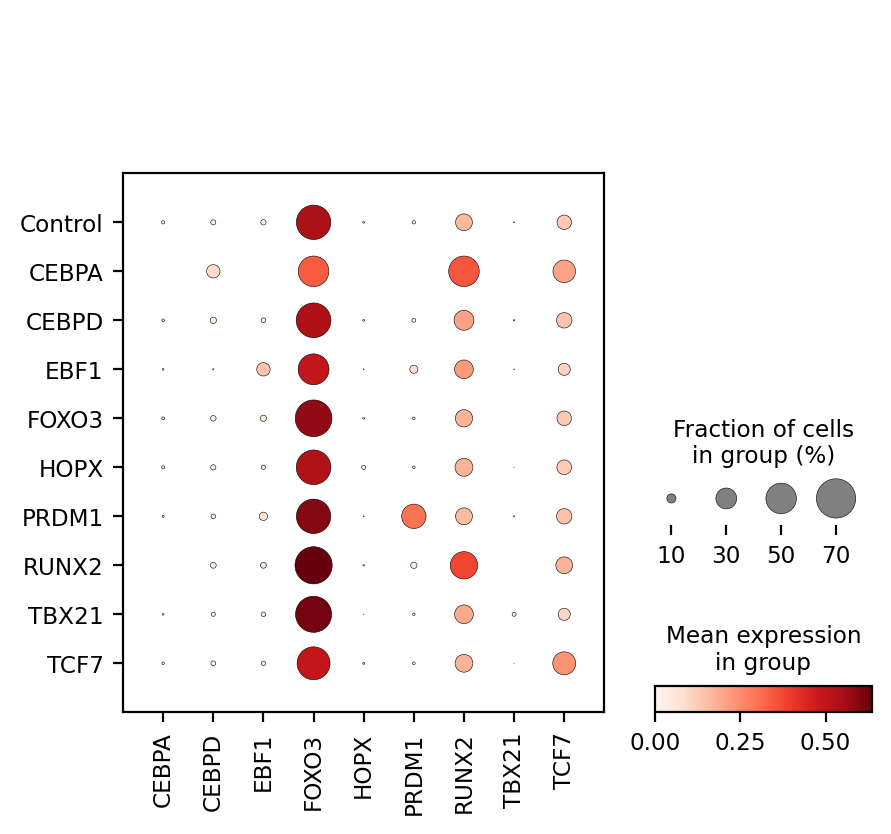

In [40]:
sc.pl.dotplot(adata, tfs, groupby='perturbation')

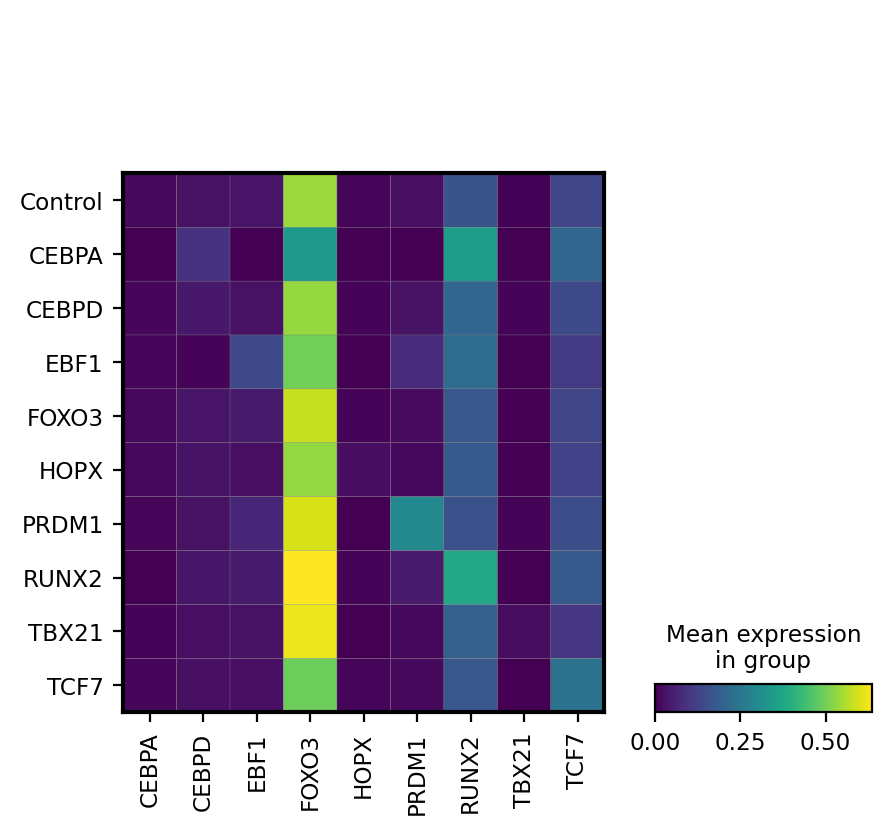

In [41]:
sc.pl.matrixplot(adata, tfs, groupby='perturbation')

In [42]:
sc.tl.rank_genes_groups(adata_ipsc_perturbed, 'perturbation', method='wilcoxon')

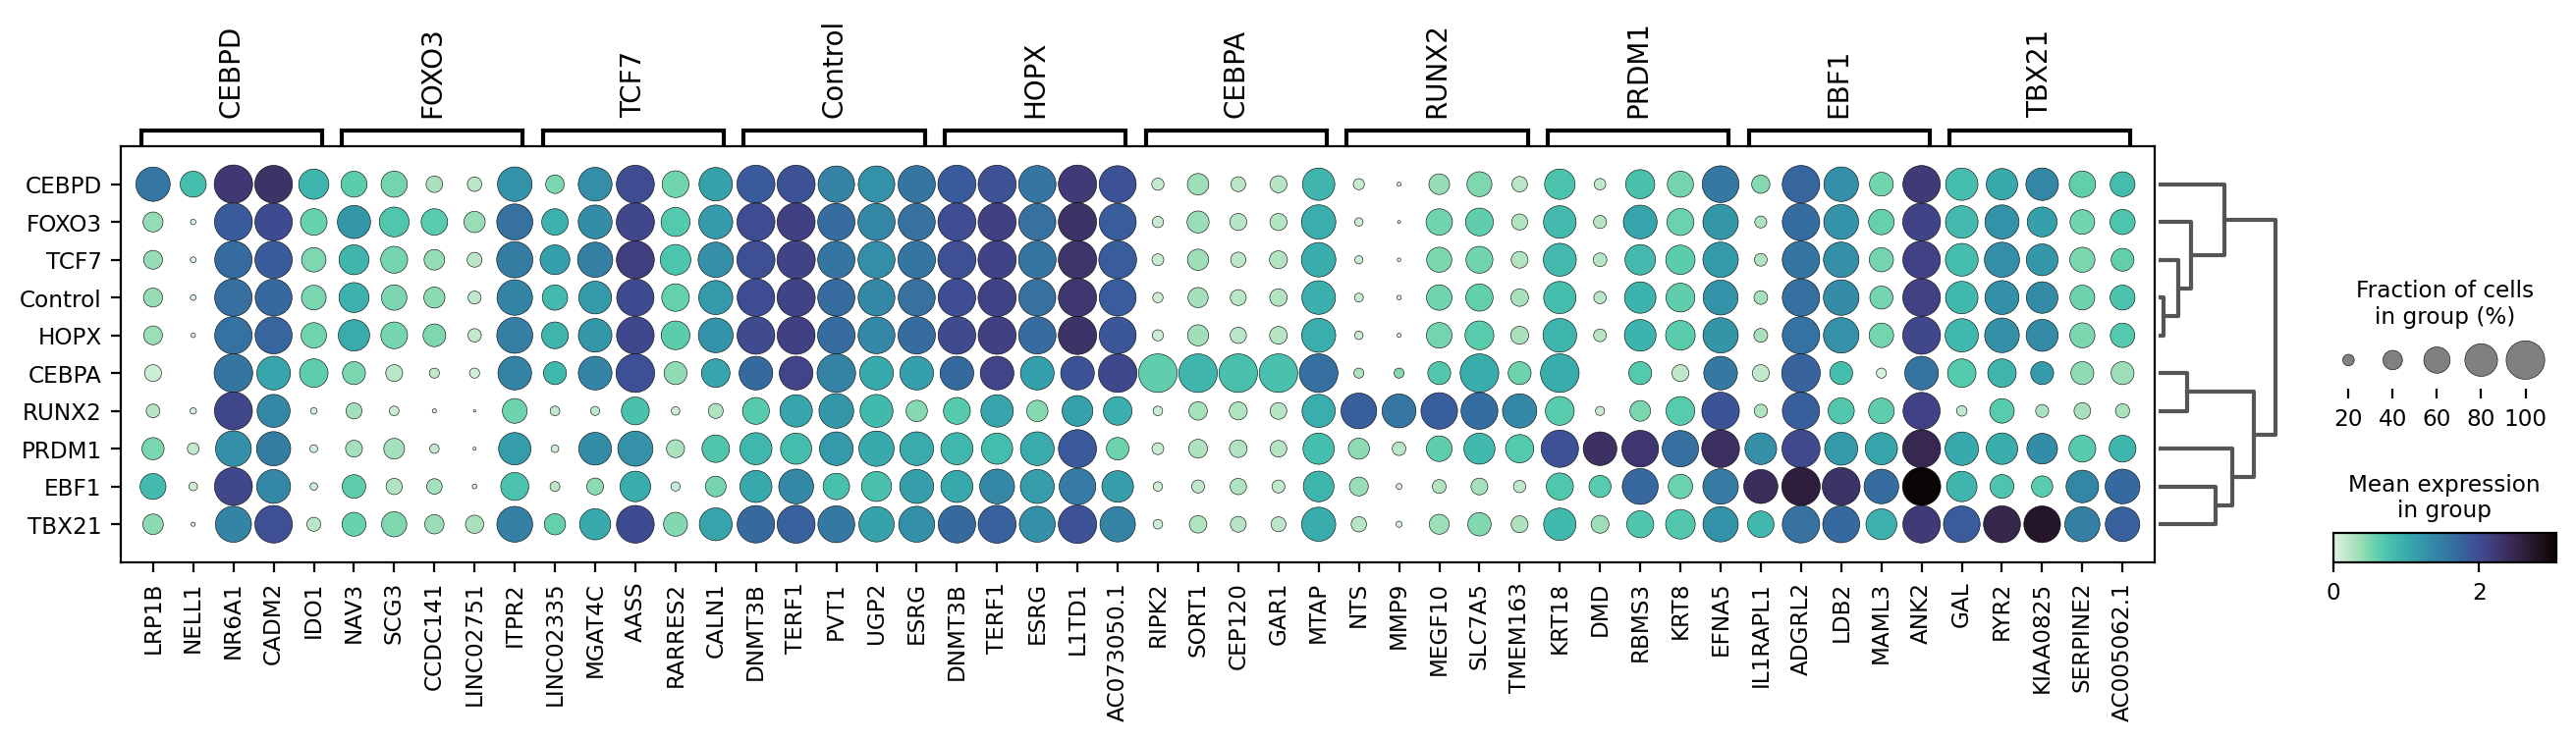

In [44]:
sc.pl.rank_genes_groups_dotplot(adata_ipsc_perturbed, n_genes=5, figsize=(16,2.75), cmap='mako_r')

In [45]:
pd.DataFrame(adata_ipsc_perturbed.uns['rank_genes_groups']['names']).head(60)

,Control,CEBPA,CEBPD,EBF1,FOXO3,HOPX,PRDM1,RUNX2,TBX21,TCF7
0,DNMT3B,RIPK2,LRP1B,IL1RAPL1,NAV3,DNMT3B,KRT18,NTS,GAL,LINC02335
1,TERF1,SORT1,NELL1,ADGRL2,SCG3,TERF1,DMD,MMP9,RYR2,MGAT4C
2,PVT1,CEP120,NR6A1,LDB2,CCDC141,ESRG,RBMS3,MEGF10,KIAA0825,AASS
3,UGP2,GAR1,CADM2,MAML3,LINC02751,L1TD1,KRT8,SLC7A5,SERPINE2,RARRES2
4,ESRG,MTAP,IDO1,ANK2,ITPR2,AC073050.1,EFNA5,TMEM163,AC005062.1,CALN1
5,JARID2,TCAF1,ROR1,FBN2,ROR1,HELLS,HPGD,ZEB2,GDF3,TOX
6,JADE1,TMTC4,DENND1B,ROR2,POLR3G,RBPJ,AL157944.1,VIM,LINC00458,LARGE1
7,RBPJ,SNX13,SLC7A8,SLIT2,CD24,CD24,MMP16,NRXN3,DTWD2,USP44
8,L1TD1,TNFRSF21,ACSS3,PCDH7,PSIP1,PEBP1,PCAT14,COL1A1,PWRN1,ANOS1
9,AC073050.1,MB21D2,SORCS1,AUTS2,LRRC4C,RMST,ROBO2,KIF26B,AC003975.1,SORCS3


In [47]:
sc.tl.rank_genes_groups(adata_ipsc_perturbed, 'perturbation', reference='Control', method='wilcoxon')

categories: Control, CEBPA, CEBPD, etc.
var_group_labels: CEBPA, CEBPD, EBF1, etc.


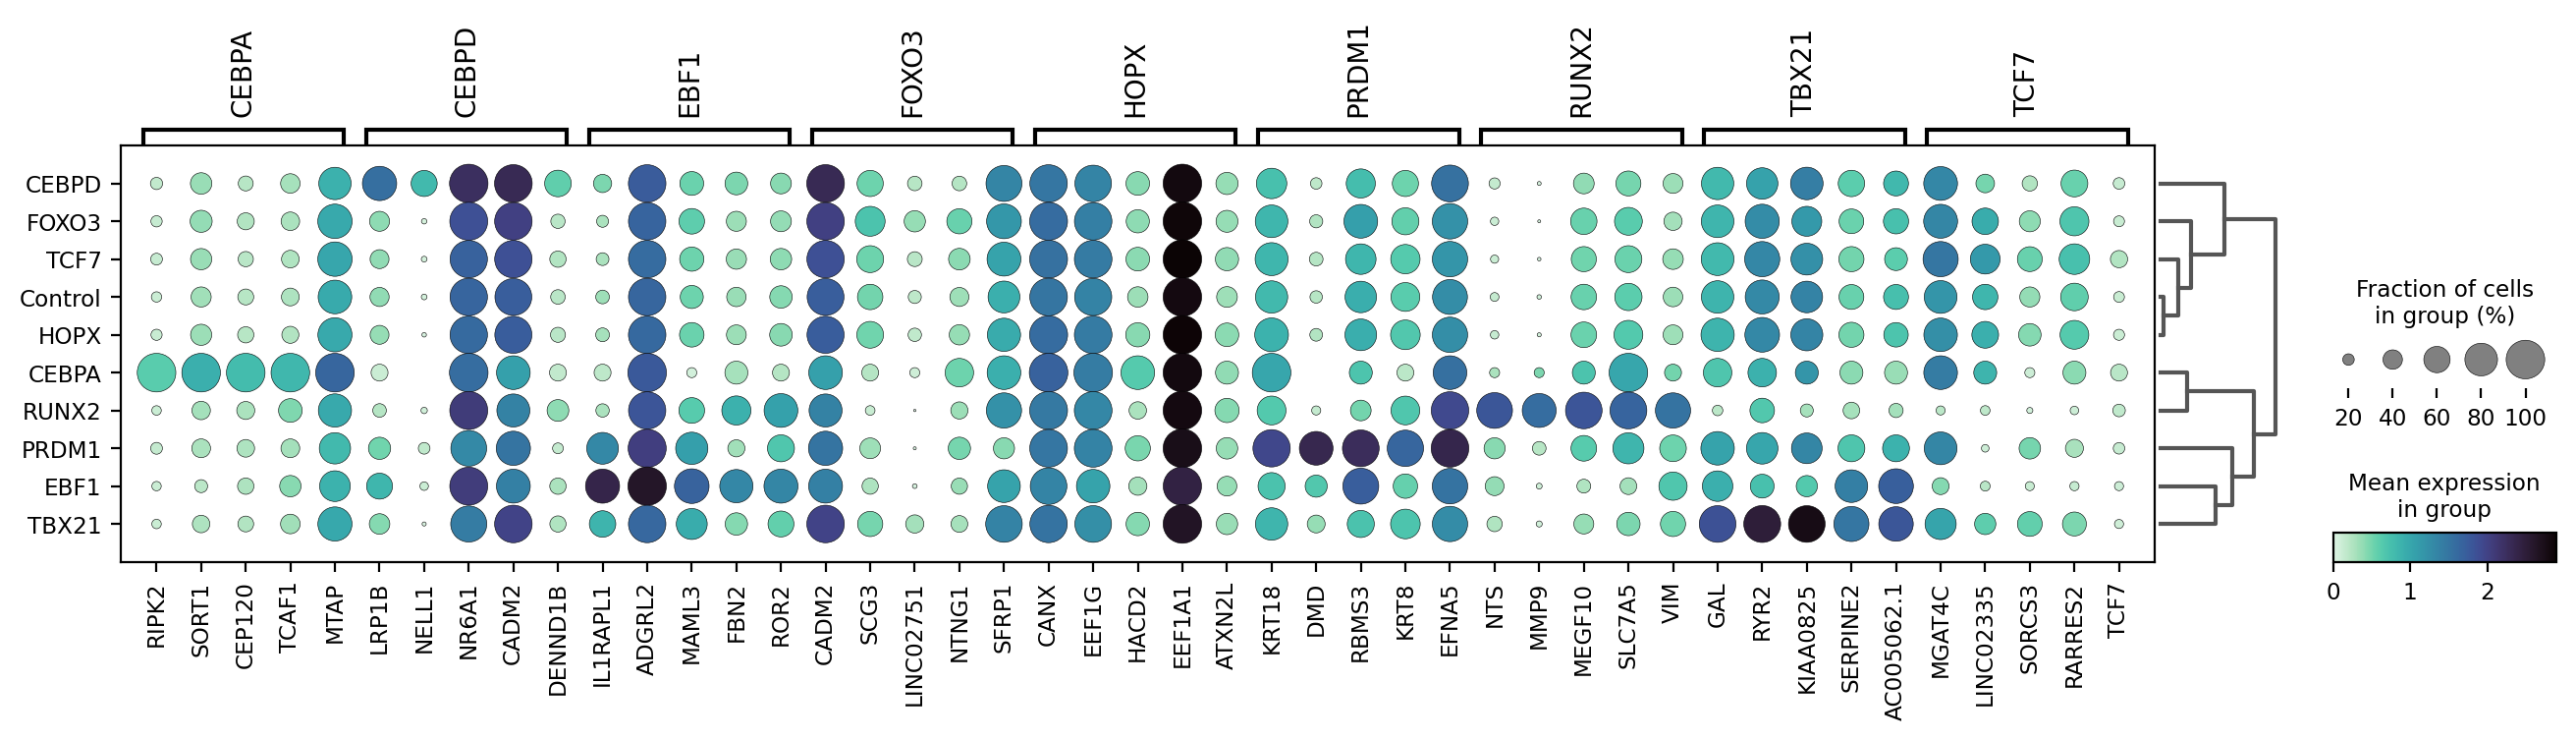

In [48]:
sc.pl.rank_genes_groups_dotplot(adata_ipsc_perturbed, n_genes=5, figsize=(16,2.75), cmap='mako_r')

In [49]:
# Extract DEGs into a dataframe
df = sc.get.rank_genes_groups_df(
    adata_ipsc_perturbed,
    group=None  # gets all groups
)

# Save to CSV
df.to_csv("ipsc_multiome_tf_degs_wilcoxon.csv", index=False)

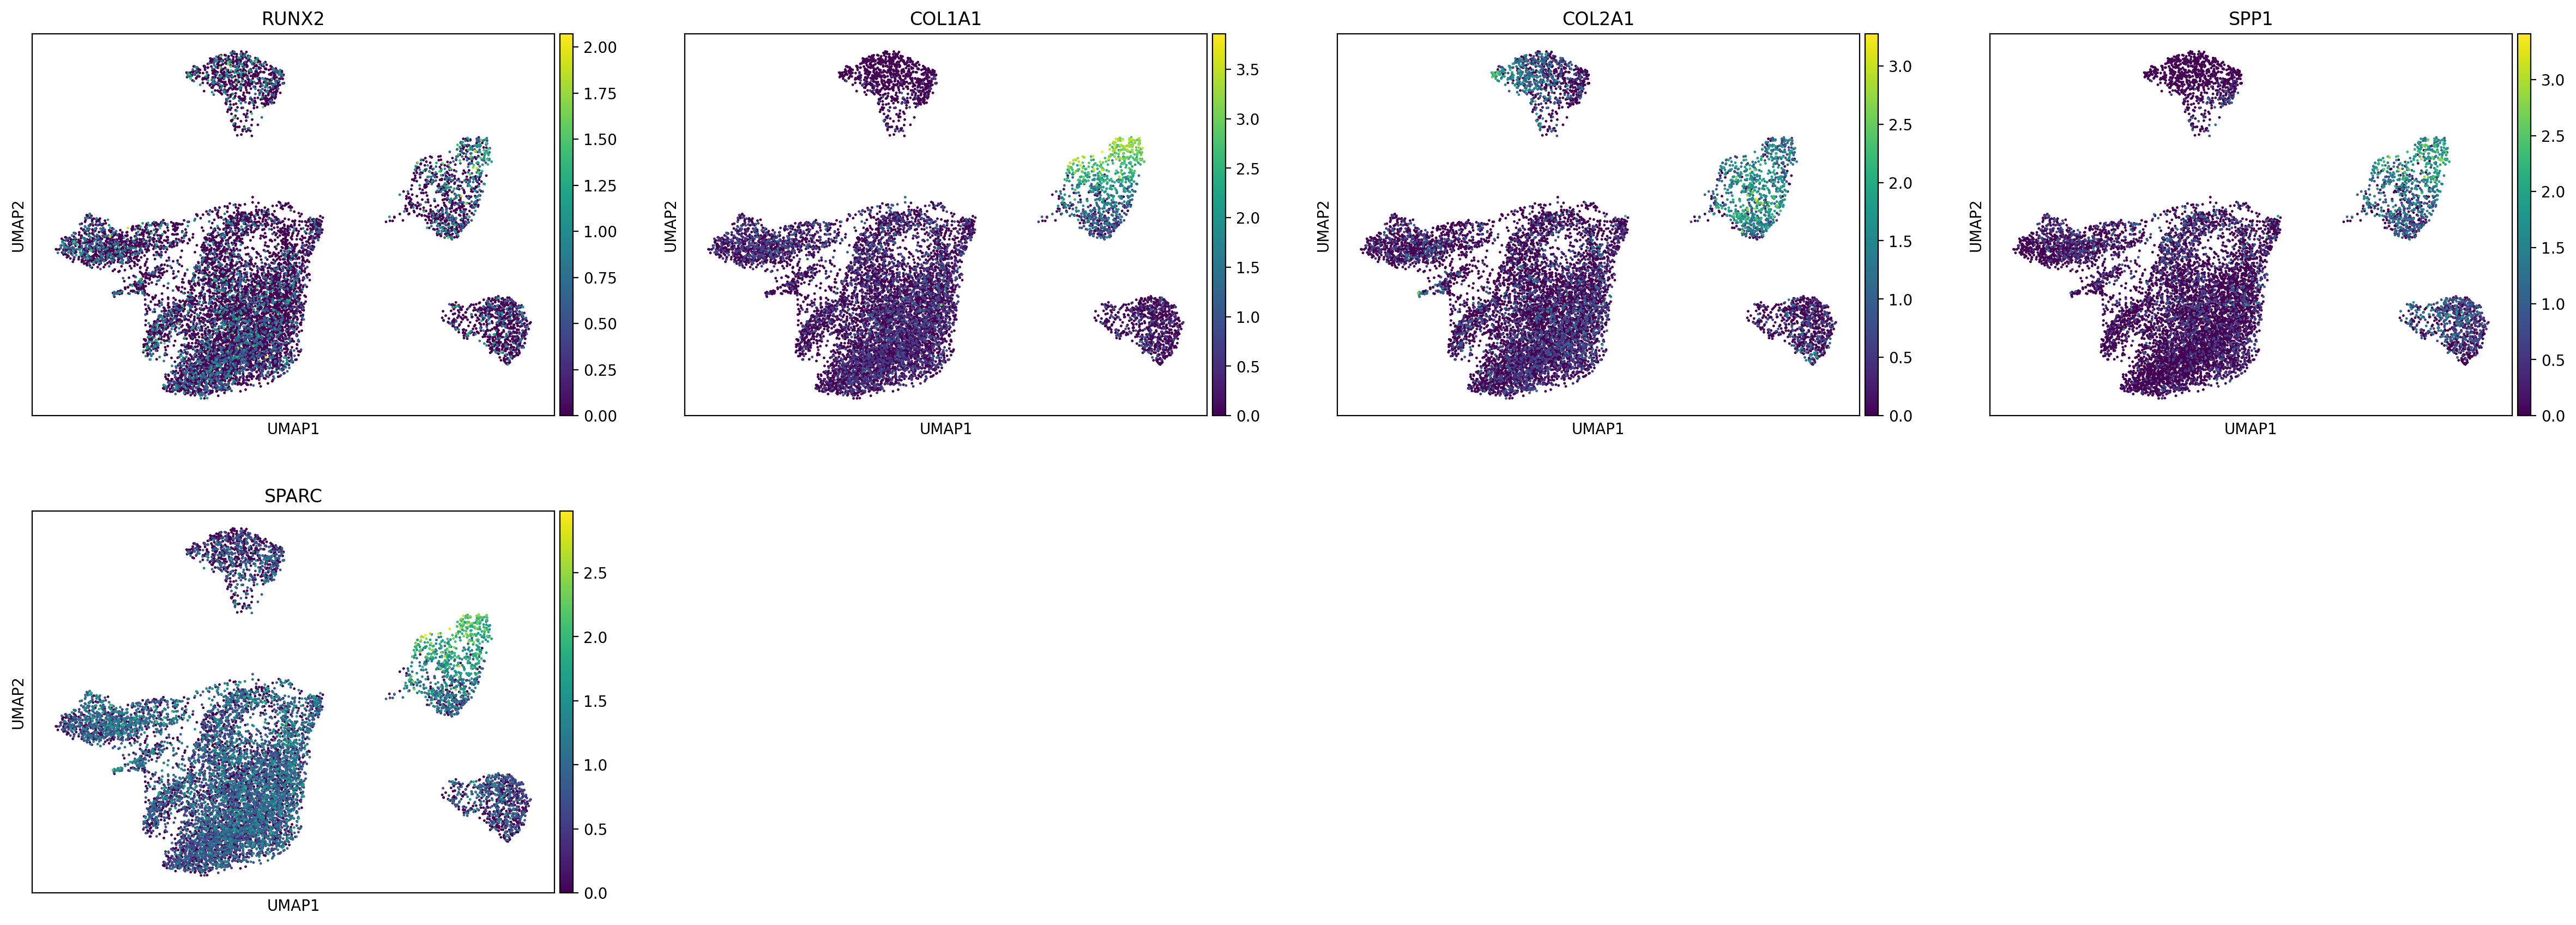

In [8]:
sc.pl.umap(adata, color=['RUNX2', 'COL1A1', 'COL2A1', 'SPP1', 'SPARC'])

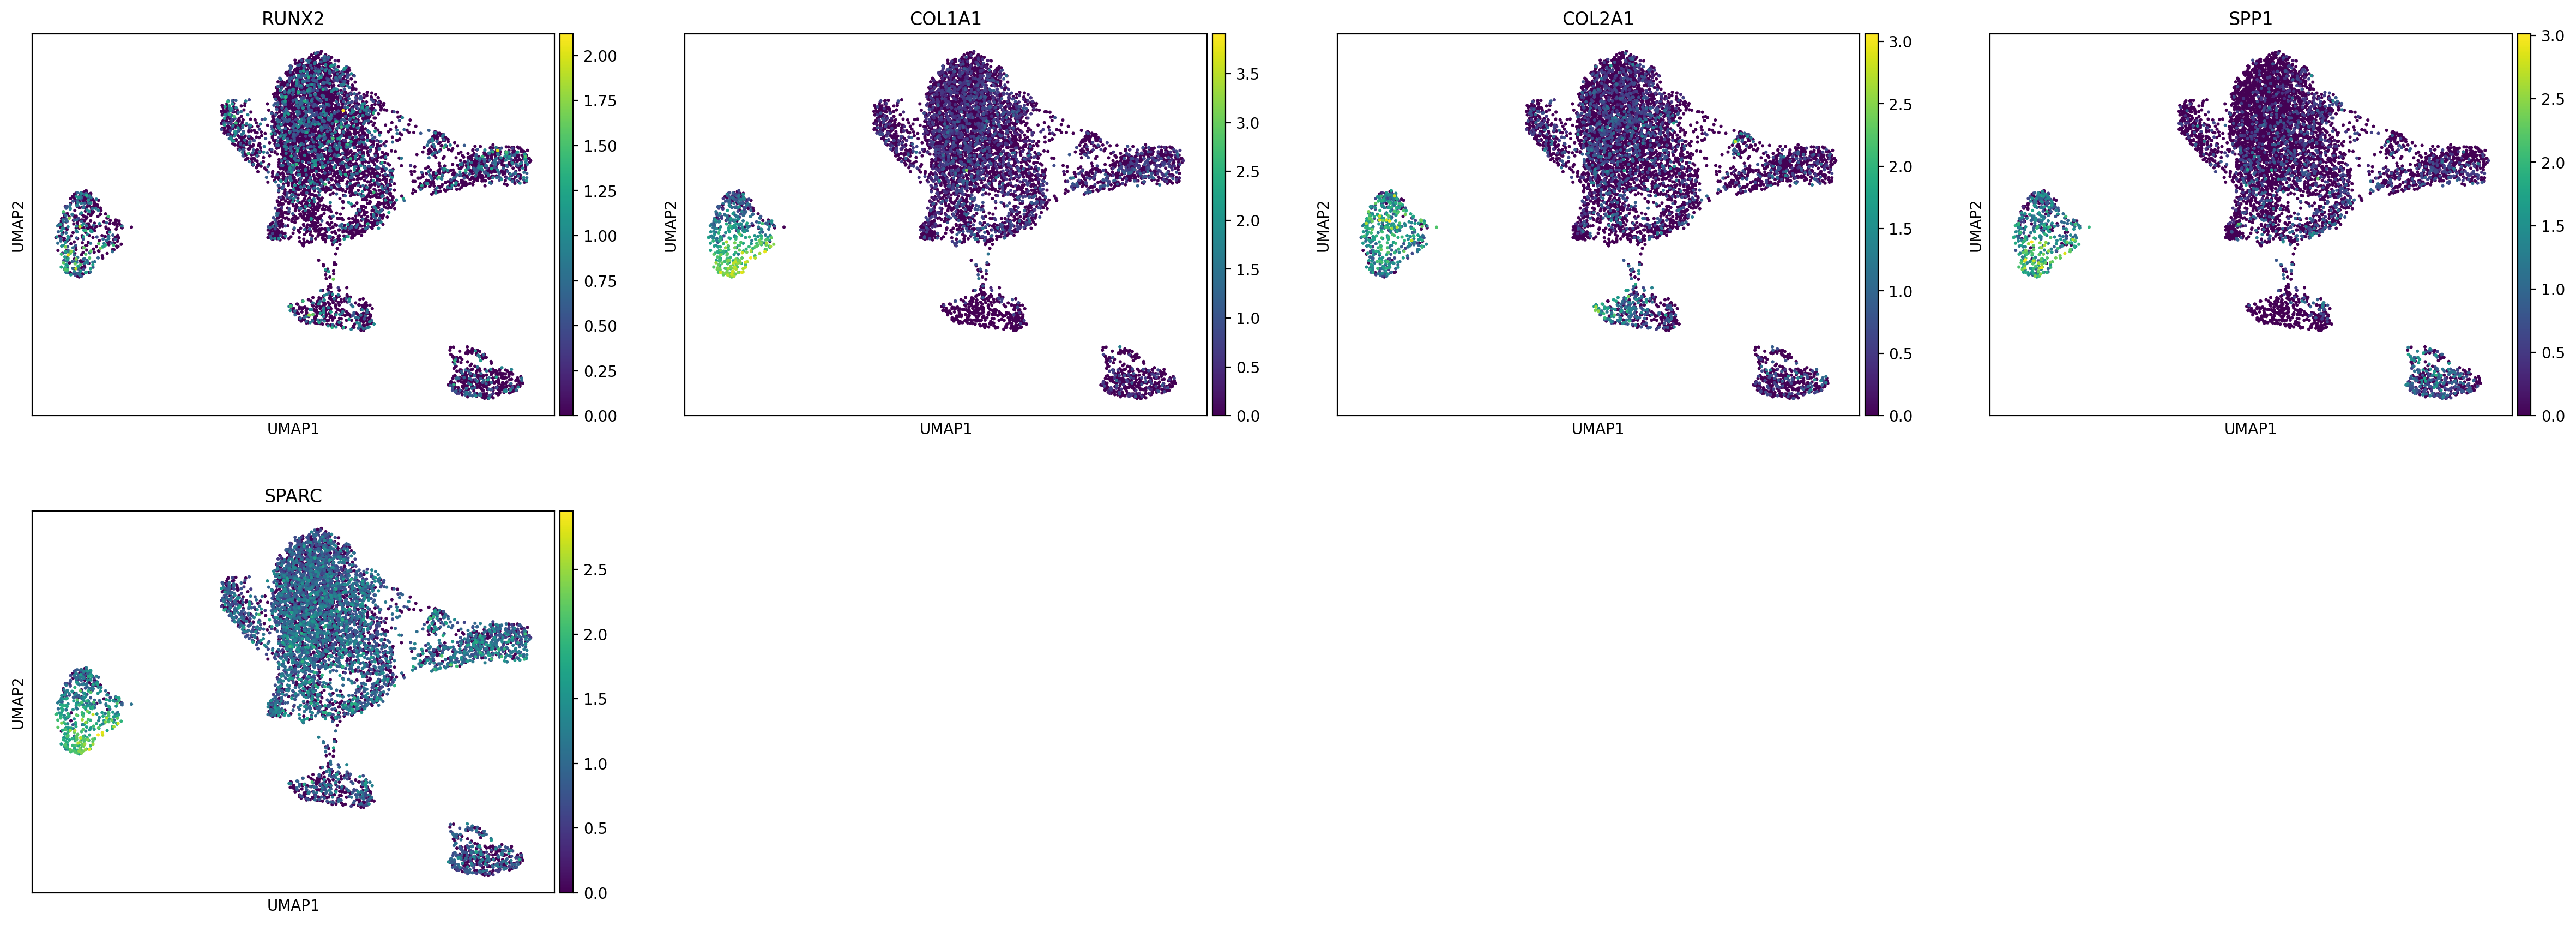

In [10]:
sc.pl.umap(adata_ipsc_perturbed, color=['RUNX2', 'COL1A1', 'COL2A1', 'SPP1', 'SPARC'])